In [1]:
# Imports
import argparse
from itertools import groupby
import pandas as pd
from IPython.display import display
from numpy.core.numeric import NaN
import numpy as np
import matplotlib.pyplot as plt
# from utils import * # fix wildcard import

In [2]:
# Functions
from IPython.display import display
from numpy.core.numeric import NaN
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def add_to_nxt_idx(lst):
    '''Given total time counts over a session as a list, 
    if the next index is less than the current one, 
    add the two and replace the next index'''
    max_so_far = lst[0]
    new_lst = []
    for x in lst:
        if x >= max_so_far:
            new_lst.append(x)
            max_so_far = x
        elif x < max_so_far:
            y = (max_so_far + x)
            new_lst.append(y)
            max_so_far = y
    return new_lst

def get_prt(lst):
    max_so_far = lst[0]
    new_lst = []
    for x in lst:
        if x >= max_so_far:
            max_so_far = x
        elif x < max_so_far:
            new_lst.append(max_so_far)
            max_so_far = x
    new_lst.append(lst[-1])
    return new_lst

def split_lst_if_less_than(lst):
    curr = lst[0]
    temp = []
    res = []
    for ele in lst:
        # if curr value greater than split
        if ele < curr:
            res.append(temp)
            curr = ele
            temp = []
        else:
            curr = ele
        temp.append(ele)
    res.append(temp)
    return res

def get_ind_patch_times(lst):
    max_so_far = lst[0]
    new_lst = []
    for x in lst:
        if x >= max_so_far:
            new_lst.append(x)
            max_so_far = x
        elif x < max_so_far:
            y = (max_so_far + x)
            new_lst.append(y)
            max_so_far = y
    return new_lst

def create_bct_trials(lst):
    size = len(lst)
    idx_list = [idx + 1 for idx, val in
            enumerate(lst) if val == 0.0]
    
    res = [lst[i: j] for i, j in zip([0] + idx_list, idx_list + ([size] if idx_list[-1] != size else []))]
    
    return res

def rmv_last_bush(list1):
    '''Fxn removes last list in list of lists if the last indx does not equal 0'''
    for idx, lst in enumerate(list1):
        if (lst[-1]) != 0:
            list1.pop(idx)
    
    return list1

def flatten(t):
    '''convert list of lists into big list'''
    return [item for sublist in t for item in sublist]


In [14]:
# 0. Take cmd argument and load data
# ap = argparse.ArgumentParser()
# ap.add_argument("-i", "--id", required=True, help="input user ID")
# args = vars(ap.parse_args())
# USER_ID = str(args["id"])

# Load data
CSV = 'frg_long.csv'
df = pd.read_csv(CSV)

# To look at groups of users:
GROUP = 100
ssn = df[df["group"] == GROUP]
# To look at individual users, pick between 0 and 491:
# USER_ID = 3
# ssn = df[df["user_id"] == USER_ID]

In [18]:
# 1. Get fast and slow sessions
fst_ssn = ssn[ssn["traveltime"] == 1] # fast env dataframe
slw_ssn = ssn[ssn["traveltime"] == 5] # slow env dataframe

cln_fst_lst = fst_ssn['BushNo'].tolist() # put trials in whole list
cln_slw_lst = slw_ssn['BushNo'].tolist() # put trials in whole list
# get list of berryct
f_ct_lst = fst_ssn["BerryCount"].tolist() # put fast env rewards in list
s_ct_lst = slw_ssn["BerryCount"].tolist() # put slow env rewards in list
f_bct_nn = np.nan_to_num(f_ct_lst) # Replace nans with 0
s_bct_nn = np.nan_to_num(s_ct_lst) 
f_bct = f_bct_nn.tolist() # array to list
s_bct = s_bct_nn.tolist()

# Put all time pts into a list per environment
fst_tott_lst = fst_ssn["TotalTime_sec"].tolist() # put all time pts in a list all times in fst env
slw_tott_lst = slw_ssn["TotalTime_sec"].tolist() # get all times in slow env


# Fig 2: Total Reward Intake by environment
fast_bct_trials_final = list(map(add_to_nxt_idx, fast_bct_trials_final))
slow_bct_trials_final = list(map(add_to_nxt_idx, slow_bct_trials_final))
fast_bct_trls_flat = flatten(fast_bct_trials_final)
slow_bct_trls_flat = flatten(slow_bct_trials_final)
fst_bct_fig1 = add_to_nxt_idx(fast_bct_trls_flat)
slw_bct_fig1 = add_to_nxt_idx(slow_bct_trls_flat)
fst_time_fig1 = add_to_nxt_idx(fst_time_final)
slw_time_fig1 = add_to_nxt_idx(slw_time_final)
# if len(fst_time_fig1) != len(fst_bct_fig1):
#     fst_time_fig1.pop(0)
# if (len(slw_time_fig1)) != len(slw_bct_fig1):
#     slw_time_fig1.pop(0)
fast, = plt.plot(fst_time_fig1, fst_bct_fig1, 'r', label='1s Travel')
slow, = plt.plot(slw_time_fig1, slw_bct_fig1,  'b', label='5s Travel')
plt.title('Fig 2: Total Intake', fontsize='x-large')
plt.ylabel('Berry Count (oz)')
plt.xlabel('Time (s)')
plt.grid(axis='x', color='0.95')
plt.legend(title = 'Environment Type')
plt.tight_layout()
plt.show()


[6.7, 6.26, 5.76, 5.2, 4.85, 4.37, 4.05, 3.49, nan, 6.82, 5.99, 5.05, 4.89, 4.27, 3.65, 3.28, nan, 7.07, 6.75, 6.34, 5.75, 5.54, 4.93, 3.96, 3.54, nan, 7.26, 6.84, 6.22, 5.4, nan, 6.95, 6.52, 6.53, 5.63, 4.7, nan, 7.3, 7.37, 6.09, 5.64, 5.22, 4.99, nan, 6.95, 6.12, 5.83, 4.76, nan, 6.77, 6.49, 6.03, 5.48, 4.66, nan, 6.8, 5.83, 5.34, nan, 7.16, 7.06, 6.78, 6.39, nan, 6.99, 5.97, 5.7, 5.08, 4.15, 3.64, 3.0, nan, 7.03, 5.95, 5.42, 4.33, 3.81, 2.97, nan, 6.69, 6.23, 6.17, 5.64, 5.24, 5.11, 4.46, 4.16, 3.89, 3.46, nan, 7.5, 6.83, 6.69, 6.32, 6.13, 5.58, 4.94, 4.23, 3.82, nan, 6.93, 6.41, 5.82, 5.27, 4.99, 4.5, 3.98, 3.41, 2.69, nan, 6.86, 6.5, 6.36, 5.41, 4.74, 4.4, 4.19, 4.08, 3.55, 2.88, 2.77, 2.35, 2.41, nan, 7.78, 7.4, 6.93, 6.53, 6.1, 5.68, 5.46, 4.81, 4.38, 3.73, 3.56, 3.15, nan, 6.75, 6.66, 6.21, 5.76, 4.8, 4.54, 4.06, 3.22, 3.09, 2.57, nan, 7.28, 6.59, 7.16, 6.58, 6.29, 5.66, 5.23, nan, 7.03, 6.51, 6.01, 5.75, nan, 6.78, 6.6, 6.18, 5.46, nan, 6.91, 5.94, 5.1, 4.39, nan, 7.21, 6.24, 

In [5]:
# Code to remove those pesky last trials 

cln_fst_lst = fst_ssn['BushNo'].tolist() # put trials in whole list
cln_slw_lst = slw_ssn['BushNo'].tolist() # put trials in whole list
cln_fst_lols = split_lst_if_less_than(cln_fst_lst) # split into the 2 blocks
cln_slw_lols = split_lst_if_less_than(cln_slw_lst) # split into the 2 blocks
fst_len_block1 = len(cln_fst_lols[0]) # get # of patches of first block
slw_len_block1 = len(cln_slw_lols[0]) # get length of first list
fst_len_block2 = len(cln_fst_lols[1]) # get # of patches of 2nd block
slw_len_block2 = len(cln_slw_lols[1]) # get length of 2nd list

cln_fst_lols_lst_idx = [item[-1] for item in cln_fst_lols] # get value of last items in each list
fst_rmvblock1 = int(cln_fst_lols_lst_idx[0]) # 6 for user 0
fst_rmvblock2 = int(cln_fst_lols_lst_idx[1]) # 7 for user 0
fst_block1lst = cln_fst_lols[0]
fst_block1lst_rmv = [s for s in fst_block1lst if s != fst_rmvblock1]
fst_block2lst = cln_fst_lols[1]
fst_block2lst_rmv = [s for s in fst_block2lst if s != fst_rmvblock2]

cln_slw_lols_lst_idx = [item[-1] for item in cln_slw_lols] # get value of last items in each list
slw_rmvblock1 = int(cln_slw_lols_lst_idx[0]) # 5 in this ex
slw_rmvblock2 = int(cln_slw_lols_lst_idx[1]) # 4 in this ex
slw_block1lst = cln_slw_lols[0]
slw_block1lst_rmv = [s for s in slw_block1lst if s != slw_rmvblock1]
slw_block2lst = cln_slw_lols[1]
slw_block2lst_rmv = [s for s in slw_block2lst if s != slw_rmvblock2]

# get list of berryct
f_ct_lst = fst_ssn["BerryCount"].tolist() # put fast env rewards in list
s_ct_lst = slw_ssn["BerryCount"].tolist() # put slow env rewards in list
f_bct_nn = np.nan_to_num(f_ct_lst) # Replace nans with 0
s_bct_nn = np.nan_to_num(s_ct_lst) 
f_bct = f_bct_nn.tolist() # array to list
s_bct = s_bct_nn.tolist()
   
# split into 2 chunks defined by len_block1,2
fst_sizes = [fst_len_block1, fst_len_block2] #### FAST FIRST
fst_it_bct = iter(f_bct)
split_fst_ssns = [[next(fst_it_bct) for _ in range(size)] for size in fst_sizes]
slw_sizes = [slw_len_block1, slw_len_block2] #### THEN SLOW
slw_it_bct = iter(s_bct)
split_slw_ssns = [[next(slw_it_bct) for _ in range(size)] for size in slw_sizes]

# Remove unneeded blocks
fst_blk1_rmv_num = fst_len_block1 - len(fst_block1lst_rmv)
fst_blk2_rmv_num = fst_len_block2 - len(fst_block2lst_rmv)
slw_blk1_rmv_num = slw_len_block1 - len(slw_block1lst_rmv)
slw_blk2_rmv_num = slw_len_block2 - len(slw_block2lst_rmv)
for i in range(0, fst_blk1_rmv_num): split_fst_ssns[0].pop()
for i in range(0, fst_blk2_rmv_num): split_fst_ssns[1].pop()
for i in range(0, slw_blk1_rmv_num): split_slw_ssns[0].pop()
for i in range(0, slw_blk2_rmv_num): split_slw_ssns[1].pop()

# merge back to one list with unneeded blocks
fst_bct_final = flatten(split_fst_ssns)
slw_bct_final = flatten(split_slw_ssns)

# Split berry ct list into trials
fst_len = len(fst_bct_final)
slw_len = len(slw_bct_final)

idx_fst_list = [idx + 1 for idx, val in enumerate(fst_bct_final) if val == 0.0] # Separate each trial by 0
fast_bct_trials_final = [fst_bct_final[i: j] for i, j in zip([0] + idx_fst_list, idx_fst_list + 
    ([fst_len] if idx_fst_list[-1] != fst_len else []))]
idx_slw_list = [idx + 1 for idx, val in enumerate(slw_bct_final) if val == 0.0]
slow_bct_trials_final = [slw_bct_final[i: j] for i, j in zip([0] + idx_slw_list, idx_slw_list + 
    ([slw_len] if idx_slw_list[-1] != slw_len else []))]

# if last item is 0, then pop
if (fast_bct_trials_final[0][0] == 0.0): fast_bct_trials_final.pop(0)
if (slow_bct_trials_final[0][0] == 0.0): slow_bct_trials_final.pop(0)

# Put all time pts into a list per environment
fst_tott_lst = fst_ssn["TotalTime_sec"].tolist() # put all time pts in a list all times in fst env
slw_tott_lst = slw_ssn["TotalTime_sec"].tolist() # get all times in slow env

# split into 2 chunks defined by len_block1,2
fst_it_time = iter(fst_tott_lst)
slw_it_time = iter(slw_tott_lst)
split_fst_ssns = [[next(fst_it_time) for _ in range(size)] for size in fst_sizes]
split_slw_ssns = [[next(slw_it_time) for _ in range(size)] for size in slw_sizes]

for i in range(0, fst_blk1_rmv_num): split_fst_ssns[0].pop()
for i in range(0, fst_blk2_rmv_num): split_fst_ssns[1].pop()
for i in range(0, slw_blk1_rmv_num): split_slw_ssns[0].pop()
for i in range(0, slw_blk2_rmv_num): split_slw_ssns[1].pop()

# merge back to one list
fst_time_final = flatten(split_fst_ssns)
slw_time_final = flatten(split_slw_ssns)

# # split into trials based on a separator
fast_time_trials_final = split_lst_if_less_than(fst_time_final)
slow_time_trials_final = split_lst_if_less_than(slw_time_final)

In [8]:
# Fig 1: Reward decreases with each 'exploit' decision
# x: time in patch
# y: cumulative reward
# SHOW THE REWARD DECREMENT FXN
# combine all users and time? hide axes

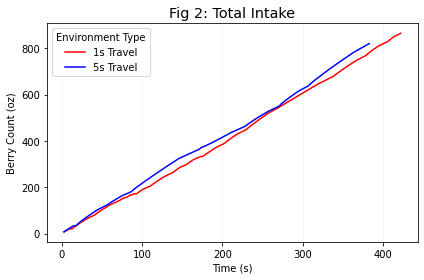

In [16]:
# Fig 2: MVT: optimal leave time depends on env
# x: time in patch (s)
# y: reward rate (oz/s)


# COMBINE THESE TWO? plot mvt with total reward intake of all users


# Fig 2: Total Reward Intake by environment
fast_bct_trials_final = list(map(add_to_nxt_idx, fast_bct_trials_final))
slow_bct_trials_final = list(map(add_to_nxt_idx, slow_bct_trials_final))
fast_bct_trls_flat = flatten(fast_bct_trials_final)
slow_bct_trls_flat = flatten(slow_bct_trials_final)
fst_bct_fig1 = add_to_nxt_idx(fast_bct_trls_flat)
slw_bct_fig1 = add_to_nxt_idx(slow_bct_trls_flat)
fst_time_fig1 = add_to_nxt_idx(fst_time_final)
slw_time_fig1 = add_to_nxt_idx(slw_time_final)
if len(fst_time_fig1) != len(fst_bct_fig1):
    fst_time_fig1.pop(0)
if (len(slw_time_fig1)) != len(slw_bct_fig1):
    slw_time_fig1.pop(0)
fast, = plt.plot(fst_time_fig1, fst_bct_fig1, 'r', label='1s Travel')
slow, = plt.plot(slw_time_fig1, slw_bct_fig1,  'b', label='5s Travel')
plt.title('Fig 2: Total Intake', fontsize='x-large')
plt.ylabel('Berry Count (oz)')
plt.xlabel('Time (s)')
plt.grid(axis='x', color='0.95')
plt.legend(title = 'Environment Type')
plt.tight_layout()
plt.show()

In [10]:
# Fig 3: Intake by Patch by Env
## how to account for consecutive exploration?

for i in range(len(fast_bct_trials_final)):
    if len(fast_time_trials_final[i]) != len(fast_bct_trials_final[i]):
        print(fast_time_trials_final[i])
        print(i)
        print(fast_bct_trials_final[i])
        fast_time_trials_final[0].pop(0)
if (len(slow_time_trials_final)) != len(slow_bct_trials_final):
    slow_time_trials_final[0].pop(0)

plt.subplots(figsize=(15,6))

# Subplot for 1s Delay
plt.subplot(1,3,1)
for i in range(len(fast_bct_trials_final)): # fix this bc i want to see all patches
    plt.plot(fast_time_trials_final[i], fast_bct_trials_final[i], drawstyle ='steps', color='r', alpha=0.3)
#     plt.title('Intake in Fast Patch ' + str(i+1))
    plt.title('1s Travel Delay')
    plt.ylabel('Berry Count (oz)')
    plt.xlabel('Time (s)')
#     plt.grid(axis='x', color='0.95')
    plt.xlim([0,750])
    plt.ylim([0,800])
#     plt.tight_layout()

# Subplot for 5s delay
plt.subplot(1,3,2)
for i in range(len(slow_bct_trials_final)):
    plt.plot(slow_time_trials_final[i], slow_bct_trials_final[i], drawstyle ='steps', color='b', alpha=0.3)
#     plt.title('Intake in Slow Patch ' + str(i+1))
    plt.title('5s Travel Delay')
#     plt.ylabel('Berry Count (oz)')
    plt.xlabel('Time (s)')
    plt.xlim([0,750])
    plt.ylim([0,800])
    
# Subplot for overlaid delays
plt.subplot(1,3,3)
for i in range(len(fast_bct_trials_final)): # fix this bc i want to see all patches
    plt.plot(fast_time_trials_final[i], fast_bct_trials_final[i], drawstyle ='steps', color='r', alpha=0.3)
#     plt.title('Intake in Fast Patch ' + str(i+1))
    plt.xlabel('Time (s)')
    plt.xlim([0,750])
    plt.ylim([0,800])
# Subplot fxn for 5s delay
# plt.subplot(1,3,2)
for i in range(len(slow_bct_trials_final)):
    plt.plot(slow_time_trials_final[i], slow_bct_trials_final[i], drawstyle ='steps', color='b', alpha=0.3)
#     plt.title('Intake in Slow Patch ' + str(i+1))
    plt.title('Overlay of Delays')
    plt.xlabel('Time (s)')
    plt.xlim([0,750])
    plt.ylim([0,800])
plt.suptitle('Fig 3: Patch Reward Intake', fontsize='x-large')
plt.tight_layout()
plt.show()

[2.46, 2.547, 5.561, 8.192, 11.075]
10
[0.0]
[2.364, 5.246, 8.129, 11.159, 14.074]
12
[6.92, 13.33, 19.47, 19.47]
[3.574, 6.555, 10.035, 12.784, 15.882, 18.68]
13
[7.35, 14.28, 20.919999999999998, 27.18, 27.18]
[2.445, 5.344, 8.075, 11.039, 13.821]
14
[7.2, 14.04, 20.47, 26.599999999999998, 32.3, 32.3]
[2.161, 5.076, 8.373, 11.772]
15
[7.01, 13.36, 19.5, 25.34, 25.34]


IndexError: pop from empty list

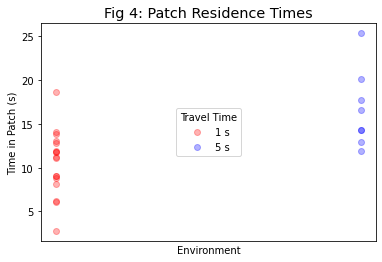

In [11]:
# Fig 4: Patch Residence Time by En

### DOUBLE CHECK THIS
fst_prt_fig3 = get_prt(fst_time_final) # Y-axis: Get bush times over session
slw_prt_fig3 = get_prt(slw_time_final) # slow env
fst_pts_fig3 = [1] * len(fst_prt_fig3) # X-axis: fast env
slw_pts_fig3 = [5] * len(slw_prt_fig3) # x-axis: slow env
fast = plt.scatter(fst_pts_fig3, fst_prt_fig3, c='r', alpha=0.3, label = '1 s')
slow = plt.scatter(slw_pts_fig3, slw_prt_fig3, c='b', alpha=0.3, label='5 s')
plt.title('Fig 4: Patch Residence Times', fontsize='x-large')
plt.ylabel('Time in Patch (s)')
plt.xlabel('Environment')
plt.tick_params(
    axis='x',          # changes apply to the x-axis
    which='both',      # both major and minor ticks are affected
    bottom=False,      # ticks along the bottom edge are off
    top=False,         # ticks along the top edge are off
    labelbottom=False) # labels along the bottom edge are off
plt.legend(title = 'Travel Time',loc=10)
plt.show()

In [ ]:
# # Fig 5: Total reward vs time in fast patch

### NEED TO FIX...

# def get_total_bct(lst):
#     '''
#     fxn: Get max time over trials over session
#     input: flattened list
#     output: list of peak times if next is time is smaller or equal
#     meaning: these peak times are the total time spent per patch
#     '''
#     max_so_far = lst[0]
#     new_lst = []
#     for x in lst:
#         if x >= max_so_far: max_so_far = x
#         elif x < max_so_far:
#             new_lst.append(max_so_far)
#             max_so_far = x
#     new_lst.append(lst[-1])
#     return new_lst

# fsttotbct_fig4 = flatten(fast_bct_trials_final)
# slwtotbct_fig4 = flatten(slow_bct_trials_final)
# fst_bct_fig4 = get_total_bct(fsttotbct_fig4) # X-axis: fast env
# slw_bct_fig4 = get_total_bct(slwtotbct_fig4) # x-axis: slow env
# print(fst_bct_fig4)
# print(fst_prt_fig3)
# print(len(slw_bct_fig4), len(slw_prt_fig3))
# fast = plt.scatter(fst_bct_fig4, fst_prt_fig3, c='r', alpha=0.3, label = '1 s')
# slow = plt.scatter(slw_bct_fig4, slw_prt_fig3, c='b', alpha=0.3, label='5 s ')
# plt.title('Fig 5: Reward by Time in Patch', fontsize='x-large')
# plt.ylabel('Time in Patch (s)')
# plt.xlabel('Total Reward')
# plt.legend(title = 'Travel Time',loc=5)
# plt.show()

In [ ]:
# Fig 6: RT vs time in patch

In [ ]:
# Fig 7: Give-up Times (GUT) vs. travel time (s)
# x: tt
# y: individual gut (s); mean GUT; optimal GUT
## look at vera's email for how she calculated this

In [ ]:
# Fig 8: ___ scores are correlated with deviation from optimal GUTs

In [ ]:
# Fig 9: variability in behavior over envs
# plot a: 
    
# x: trial number (AKA patch?)
# y: number of exploits
# plot in order of blocks...

# plot b:
# 2 separate figs for each env
# x: variability (coef of variation) in # of exploits
# y: avg response to change in env

In [ ]:
### user removed bc all explore: 59, 139, 247, 300 
### user removed bc RT negatively coded: 74

In [ ]:
#### THOUGHTS

# rt analyses ... # rt over time in a patch

# find analytic soln to what they should do; oft from stephenson, krebs, take first derivative, set to 0, solve and plot optimal in prt

# model that best describes behavior... best fit threshold model
# gain-modulated threshold model
## fit threshold to each individual that best describes leave decisions
## find value of leaving vs value of staying

# before modeling, how can i even fit a model to this behavior? where are my probabilities coming from? noisy action selection mechanism?
# ddm? for patch leaving... as an evidence accumulation task
# patch leave time given patch characteristics
# where are the probs coming from??

# include every subject in each plot (unless it's individual specific)
# statistically characterize EVERY findinge.g., run paired t-tests across subjects on prt for each travel time

# send dave plots and stats

# what regressions can we do with surveys?

In [ ]:
#### QUESTIONS
# 1. How do I access task javascript? 
# 2. How do I get reward decrement fxn?